# Laboratorio 2 · Hipótesis de asociación

Alpha = 0.0500. Se decide con precisión completa; p pequeños se presentan como <0.0001. Los p-valores son exploratorios y nominales por las dependencias temporales y de cuenta.

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image
ROOT = Path.cwd() if (Path.cwd() / 'src').is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))
from engine import fmt, pformat, load_dataset, run_full_analysis, descriptive_stats
from narrative import sections
r = json.loads((ROOT / 'results/analysis_summary.json').read_text(encoding='utf-8'))
h = pd.read_csv(ROOT / 'results/hourly_series.csv')
pd.options.display.float_format = lambda x: f'{x:.4f}'
def tabla(rows):
    frame = pd.DataFrame(rows)
    for col in frame:
        if col.endswith('_p') or col == 'p_value': frame[col] = frame[col].map(pformat)
    display(frame)
def apartado(i):
    title, texts = sections(r)[i-1]
    display(Markdown('## ' + title))
    for text in texts: display(Markdown(text))
def figura(name):
    display(Image(filename=str(ROOT / 'results/figures' / name), width=850))


In [2]:
apartado(4)
tabla(r["continuous_association"])

## 4. Covarianza y correlaciones

Como solo hay una continua original, se explicita la adaptación del requisito: pares de continuas derivadas por hora (monto_promedio, monto_mediano) y (monto_total, monto_promedio). Se incluye step-monto como análisis adicional con step discreta. Las tres pruebas contrastan asociación nula de distinto tipo: Pearson lineal, Spearman monotónica por rangos y Kendall concordancia de pares con corrección por empates.

step vs monto (n=200000, Transacciones; step discreta. P nominal bajo independencia.): covarianza=1892173.2297; Pearson=0.0235 (p=<0.0001); Spearman=0.0004 (p=0.8729); Kendall=0.0001 (p=0.9582).

monto_promedio vs monto_mediano (n=743, Horas; continuas derivadas. P nominal por dependencia temporal.): covarianza=575819150580.5616; Pearson=0.8067 (p=<0.0001); Spearman=0.9019 (p=<0.0001); Kendall=0.7339 (p=<0.0001).

monto_total vs monto_promedio (n=743, Horas; continuas derivadas. P nominal por dependencia temporal.): covarianza=-735612500850691.2500; Pearson=-0.2873 (p=<0.0001); Spearman=-0.4944 (p=<0.0001); Kendall=-0.2151 (p=<0.0001).

step vs monto (n=189359, Sensibilidad IQR de la misma muestra.): covarianza=-174078.4140; Pearson=-0.0102 (p=<0.0001); Spearman=-0.0017 (p=0.4548); Kendall=-0.0013 (p=0.4019).

Los diagramas permiten revisar colas, puntos influyentes y curvatura. La sensibilidad IQR vuelve a estimar los tres índices sobre el mismo subconjunto de la muestra, y permite ver cuánto cambia Pearson al reducir extremos. Un coeficiente pequeño puede producir p pequeño con n grande. Spearman y Kendall son más resistentes a magnitudes extremas, pero una relación no monotónica también puede tener correlación por rangos cercana a cero.

La covarianza depende de unidades. monto_total = conteo * monto_promedio, de modo que su asociación con monto_promedio tiene un componente algebraico compartido. Ninguna correlación establece causalidad. Las horas sucesivas y las cuentas repetidas comprometen independencia: los p-valores son nominales exploratorios, no inferencia causal ni garantía de rendimiento fuera de muestra.

,estado,left,right,n,alcance,covarianza_muestral,pearson_coef,pearson_p,spearman_coef,spearman_p,kendall_coef,kendall_p
0,calculado,step,monto,200000,Transacciones; step discreta. P nominal bajo i...,1892173.2297,0.0235,<0.0001,0.0004,0.8729,0.0001,0.9582
1,calculado,monto_promedio,monto_mediano,743,Horas; continuas derivadas. P nominal por depe...,575819150580.5616,0.8067,<0.0001,0.9019,<0.0001,0.7339,<0.0001
2,calculado,monto_total,monto_promedio,743,Horas; continuas derivadas. P nominal por depe...,-735612500850691.2500,-0.2873,<0.0001,-0.4944,<0.0001,-0.2151,<0.0001
3,calculado,step,monto,189359,Sensibilidad IQR de la misma muestra.,-174078.4140,-0.0102,<0.0001,-0.0017,0.4548,-0.0013,0.4019


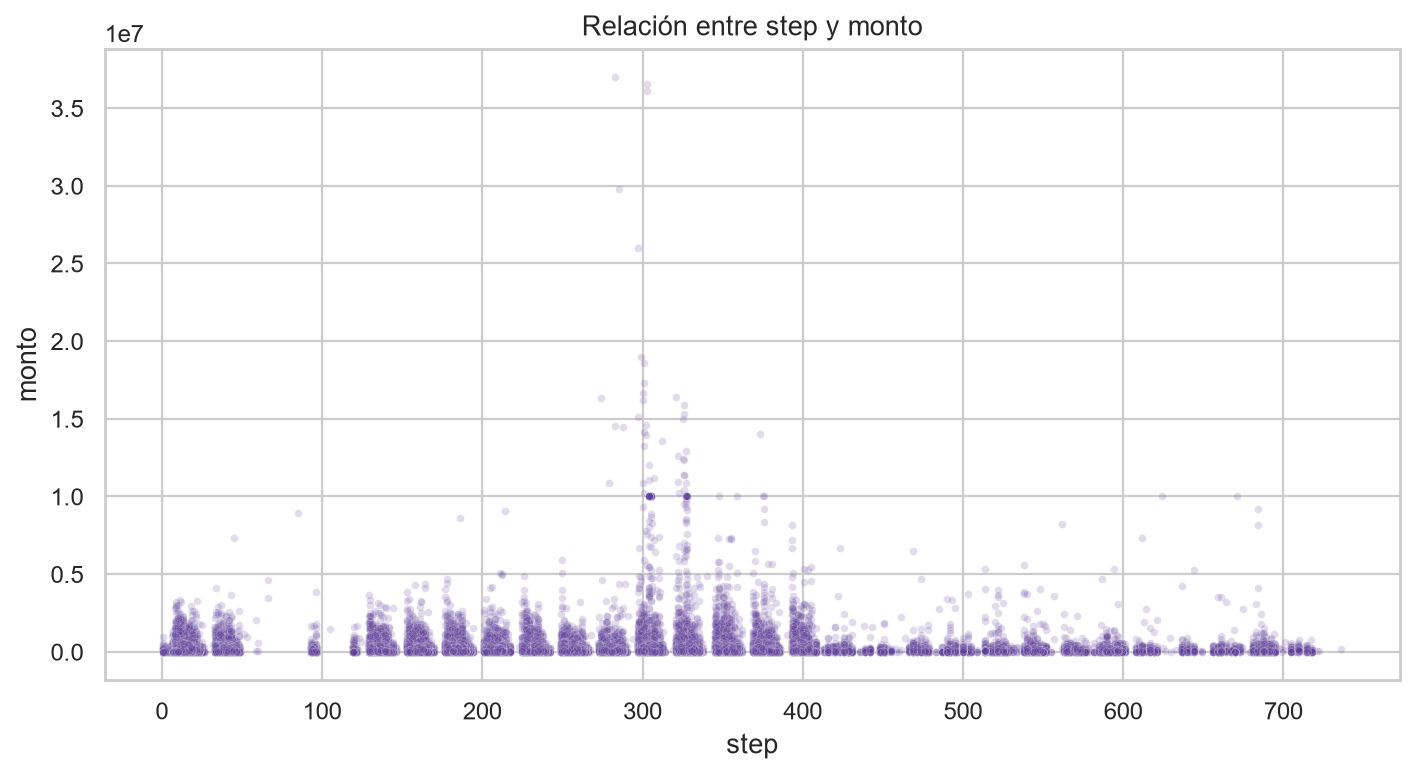

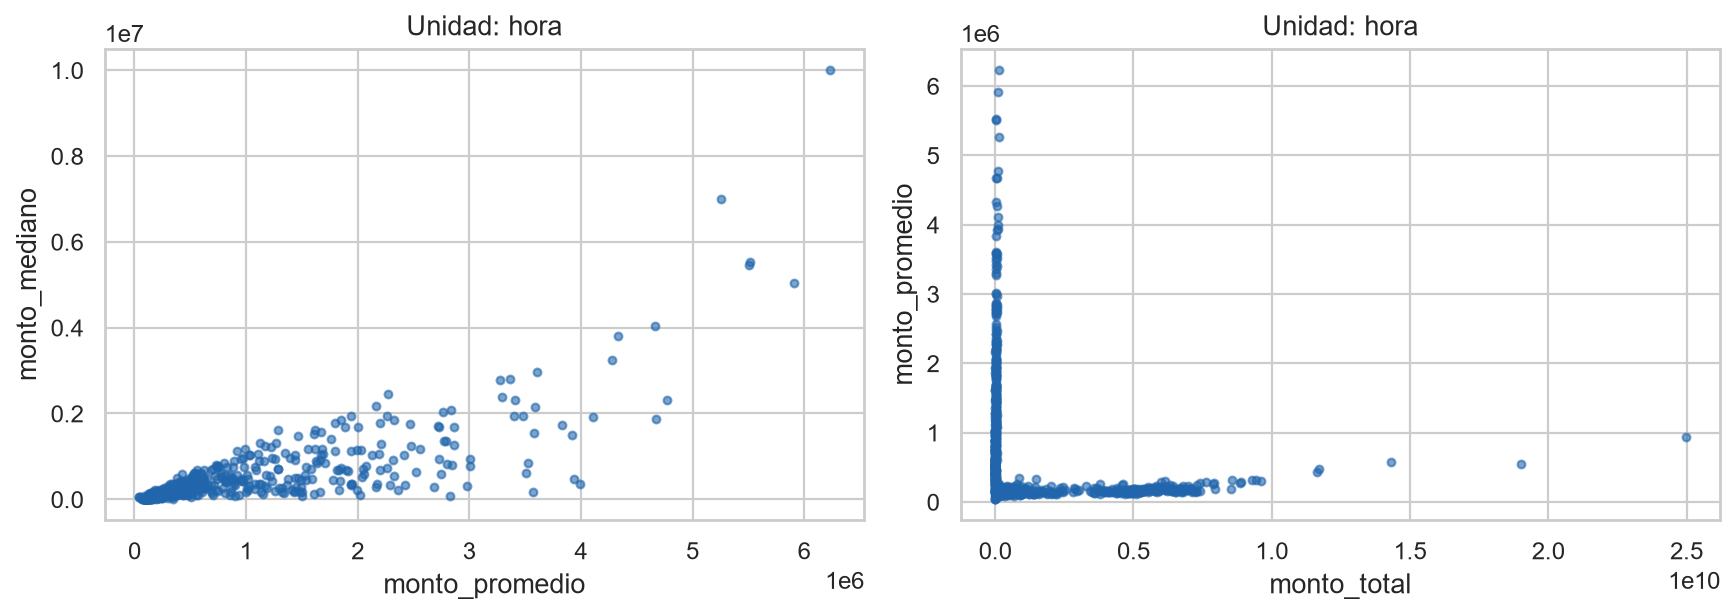

In [3]:
figura('scatter_step_monto.png')
figura('scatter_montos_horarios.png')

In [4]:
# Covarianza y Pearson independientes para el par de continuas horarias.
from scipy import stats
expected = next(a for a in r['continuous_association'] if a['left']=='monto_promedio')
assert np.isclose(h.monto_promedio.cov(h.monto_mediano), expected['covarianza_muestral'])
assert np.isclose(stats.pearsonr(h.monto_promedio,h.monto_mediano).statistic,expected['pearson_coef'])
print('Covarianza y Pearson horario reconciliados.')

Covarianza y Pearson horario reconciliados.


In [5]:
apartado(5)

## 5. Independencia categórica e información mutua

Se estudian dos pares: tipo_transaccion vs tipo_cuenta_destino (ambas originales) y tipo_transaccion vs franja_horaria (derivada de step % 24 en bloques 00-05, 06-11, 12-17, 18-23). La franja es una adaptación temporal explícita. Se evita probar millones de identificadores nominales con frecuencias esperadas insuficientes. H0: independencia; H1: dependencia. Chi-cuadrado de Pearson sin corrección de Yates.

tipo_transaccion_vs_tipo_cuenta_destino: chi2=6362620.0000, gl=4, p=<0.0001, MI=0.6398 nats, NMI=0.6570, V de Cramér=1.0000. Mínima esperada=14010.0683, porcentaje de celdas esperadas <5=0.0000%. A alpha=0.0500, se rechaza independencia.

tipo_transaccion_vs_franja_horaria: chi2=49171.8336, gl=12, p=<0.0001, MI=0.0036 nats, NMI=0.0029, V de Cramér=0.0508. Mínima esperada=733.2593, porcentaje de celdas esperadas <5=0.0000%. A alpha=0.0500, se rechaza independencia.

Las tablas observadas y esperadas están en CSV y en los notebooks; esperada(i,j)=total_fila(i)*total_columna(j)/n. MI se obtiene con logaritmo natural y es una magnitud de dependencia, no un p-valor. NMI usa 2 MI/(H(X)+H(Y)); no debe confundirse con MI en nats.

La relación tipo-destino se explica por la regla observada: PAYMENT se dirige a COMERCIO y los otros tipos a CLIENTE. Esto implica redundancia para ciertos modelos; no mide fraude. Para la franja se compara el tamaño de efecto y MI con el p-valor, porque millones de filas permiten detectar efectos pequeños. Las reglas simuladas y la dependencia temporal limitan su generalización.

In [6]:
for pair in r['categorical_association']:
    display(Markdown('### ' + pair['pair']))
    observed = pd.DataFrame(pair['observed']).set_index(pair['left'])
    expected = pd.DataFrame(pair['expected']).set_index(pair['left'])
    display(observed); display(expected)
    manual = np.outer(observed.sum(axis=1), observed.sum(axis=0))/observed.to_numpy().sum()
    assert np.allclose(expected.to_numpy(), manual)
    assert np.isclose(((observed.to_numpy()-manual)**2/manual).sum(), pair['chi2'])
    tabla([{k:pair[k] for k in ['chi2','p_value','degrees_freedom','mutual_information_nats','normalized_mutual_information','cramers_v','min_expected','percent_expected_below_5']}])

### tipo_transaccion_vs_tipo_cuenta_destino

,CLIENTE,COMERCIO
tipo_transaccion,,
CASH_IN,1399284,0
CASH_OUT,2237500,0
DEBIT,41432,0
PAYMENT,0,2151495
TRANSFER,532909,0


,CLIENTE,COMERCIO
tipo_transaccion,,
CASH_IN,926121.6031,473162.3969
CASH_OUT,1480898.1501,756601.8499
DEBIT,27421.9317,14010.0683
PAYMENT,1423975.4035,727519.5965
TRANSFER,352707.9116,180201.0884


,chi2,p_value,degrees_freedom,mutual_information_nats,normalized_mutual_information,cramers_v,min_expected,percent_expected_below_5
0,6362620.0000,<0.0001,4,0.6398,0.6570,1.0000,14010.0683,0.0000


### tipo_transaccion_vs_franja_horaria

,00-05,06-11,12-17,18-23
tipo_transaccion,,,,
CASH_IN,19329,271545,604705,503705
CASH_OUT,18233,416324,992042,810901
DEBIT,3345,6941,15228,15918
PAYMENT,61866,397036,846174,846419
TRANSFER,9832,102716,231635,188726


,00-05,06-11,12-17,18-23
tipo_transaccion,,,,
CASH_IN,24764.3856,262711.1934,591544.3190,520264.1021
CASH_OUT,39599.0469,420083.6251,945898.3406,831918.9874
DEBIT,733.2593,7778.7284,17515.2894,15404.7229
PAYMENT,38076.9391,403936.4555,909539.9108,799941.6946
TRANSFER,9431.3691,100051.9976,225286.1402,198139.4930


,chi2,p_value,degrees_freedom,mutual_information_nats,normalized_mutual_information,cramers_v,min_expected,percent_expected_below_5
0,49171.8336,<0.0001,12,0.0036,0.0029,0.0508,733.2593,0.0000


In [7]:
apartado(6)
tabla(r["mixed_association"]["normalidad_por_grupo"])
tabla(r["mixed_association"]["group_summary"])

## 6. Variable mixta: monto por tipo de transacción

H0 de Shapiro-Wilk: distribución normal dentro de cada grupo. Se toman hasta 5000 montos aleatorios por grupo porque el p de Shapiro puede ser impreciso por encima de ese tamaño. H0 de Levene centrado en la mediana: varianzas iguales. ANOVA clásica contrasta igualdad de medias; Kruskal-Wallis contrasta igualdad de distribuciones/rangos. Con formas similares puede interpretarse como contraste de localización/medianas, condición que aquí no se da por supuesta.

Shapiro en CASH_IN: n_total=1,399,284, n_test=5000, W=0.9212, p=<0.0001.

Shapiro en CASH_OUT: n_total=2,237,500, n_test=5000, W=0.4636, p=<0.0001.

Shapiro en DEBIT: n_total=41,432, n_test=5000, W=0.3114, p=<0.0001.

Shapiro en PAYMENT: n_total=2,151,495, n_test=5000, W=0.8318, p=<0.0001.

... (2 outputs left out)

Como contraste de medias con heterocedasticidad se añade ANOVA de Welch: F=1039325.8302, p=<0.0001. Las pruebas globales significativas indican al menos un grupo diferente, sin identificar por sí solas qué parejas difieren.

En estos resultados se rechazan normalidad por grupo y homogeneidad de varianzas. Se prioriza Kruskal para diferencias distribucionales y Welch para medias. ANOVA clásica se reporta por exigencia de la guía. Kruskal no corrige dependencia entre operaciones ni convierte automáticamente el resultado en una comparación exclusiva de medianas. Para inferencia confirmatoria se necesitarían bloques horarios o agrupación por cuenta, además de post hoc si se requiere localizar diferencias.

,grupo,n_total,n_shapiro,W,p_value
0,CASH_IN,1399284,5000,0.9212,<0.0001
1,CASH_OUT,2237500,5000,0.4636,<0.0001
2,DEBIT,41432,5000,0.3114,<0.0001
3,PAYMENT,2151495,5000,0.8318,<0.0001
4,TRANSFER,532909,5000,0.2662,<0.0001


,grupo,n,media,mediana,desviacion
0,CASH_IN,1399284,168920.2420,143427.7100,126508.2553
1,CASH_OUT,2237500,176273.9643,147072.1850,175329.7445
2,DEBIT,41432,5483.6653,3048.9900,13318.5355
3,PAYMENT,2151495,13057.6047,9482.1900,12556.4502
4,TRANSFER,532909,910647.0096,486308.3900,1879573.5289


,prueba,estadistico,p_value
0,Levene mediana,177416.1244,<0.0001
1,ANOVA clásica,278715.5421,<0.0001
2,Welch ANOVA,1039325.8302,<0.0001
3,Kruskal-Wallis,3906986.6819,<0.0001


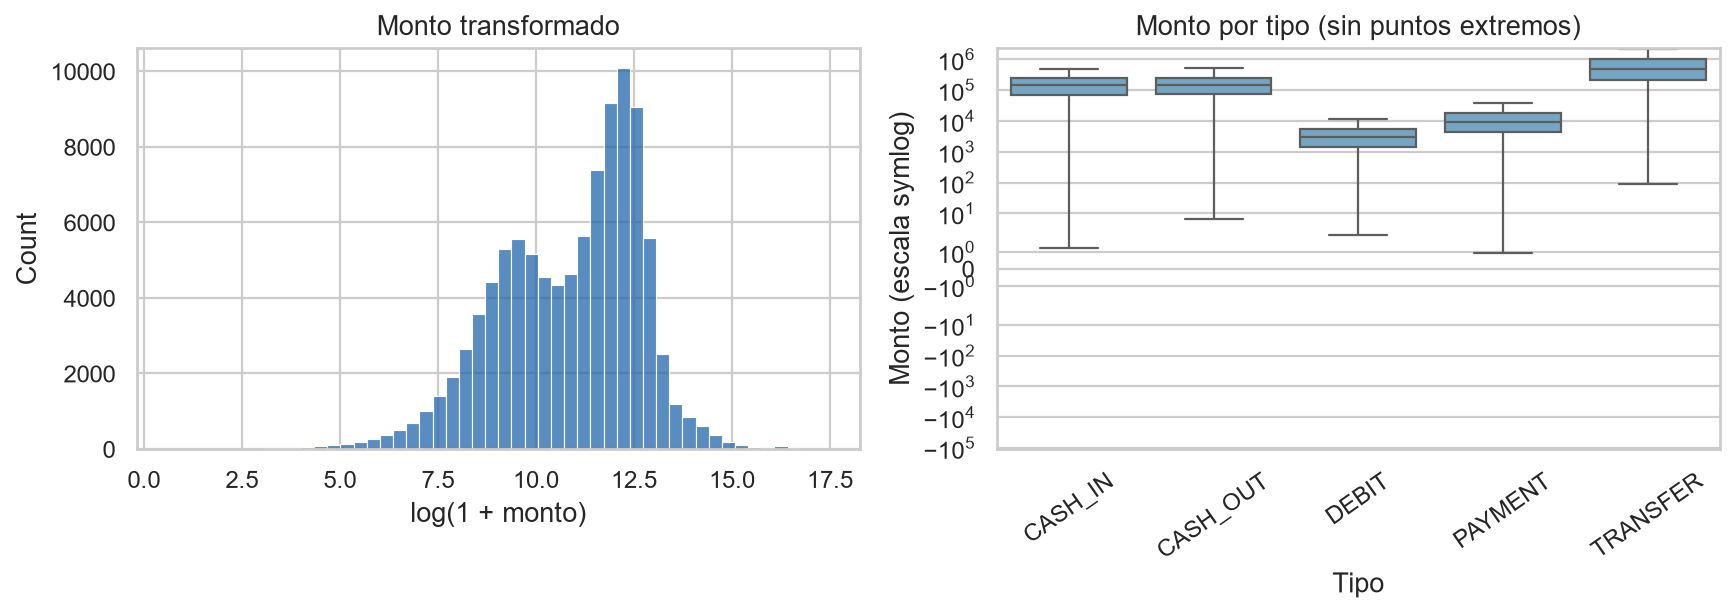

In [8]:
mix=r['mixed_association']
tabla([{'prueba': 'Levene mediana', 'estadistico':mix['levene_median_center']['statistic'], 'p_value':mix['levene_median_center']['p_value']},
       {'prueba': 'ANOVA clásica', 'estadistico':mix['anova']['F'], 'p_value':mix['anova']['p_value']},
       {'prueba': 'Welch ANOVA', 'estadistico':mix['welch_anova']['F'], 'p_value':mix['welch_anova']['p_value']},
       {'prueba': 'Kruskal-Wallis', 'estadistico':mix['kruskal_wallis']['H'], 'p_value':mix['kruskal_wallis']['p_value']}])
figura('monto_transformado_grupos.png')

Las pruebas son globales. Rechazar una hipótesis de igualdad no identifica qué pares difieren. No se interpreta Kruskal como igualdad exclusiva de medianas con distribuciones de forma distinta. Si se requieren comparaciones post hoc deben añadirse con control de multiplicidad.